# U.S. Newsstream random-article benchmark: Warriner + NRC-VAD

This notebook analyses the 41 annual `usnews-YYYY-sample1000` datasets already transferred to the **`univermelb3`** TDM Studio Workbench.

## Main design

For each randomly sampled news article, the notebook:

1. extracts full article text from the ProQuest XML;
2. tokenizes and lemmatizes with spaCy;
3. excludes stop words, punctuation, whitespace, and non-alphabetic tokens;
4. calculates **article-level Valence and Arousal** using:
   - **Warriner** ratings; and
   - **NRC-VAD v2.1 unigram** ratings;
5. records lexicon coverage;
6. averages the article-level scores within each year, so every sampled article receives equal weight.

### Why NRC-VAD is also lemma-matched

The primary NRC-VAD sensitivity analysis in the ADHD paper retained the same lemmatized preprocessing used for Warriner so that the comparison isolated **lexicon choice/coverage** rather than changing both the lexicon and preprocessing simultaneously.

This notebook therefore treats **lemma-matched NRC-VAD** as the main NRC sensitivity benchmark.

It also calculates an **exploratory surface-form NRC-VAD score** (same token filtering, but matching lower-cased surface forms rather than lemmas). This lets you inspect whether avoiding lemmatization materially changes the random-news trend, without making that less-comparable version the default.

### Reportable descriptive statistics

The notebook saves:

- annual **M, SD, SE, and 95% CI** across the 1,000 article-level scores;
- annual lexicon-coverage M and SD;
- overall article-level **M and SD across the entire 41,000-article corpus**;
- M and SD of the **annual means** across years;
- annual coverage M and SD across years;
- correlations among Warriner, NRC-lemma, and NRC-surface annual trajectories.

### Breadth

Breadth is deliberately **not** calculated here. Semantic heterogeneity among arbitrary random news articles/sentences is not conceptually equivalent to target-centred SIBling Breadth.


In [1]:
from pathlib import Path
import gc
import hashlib
import os
import re
import warnings

import numpy as np
import pandas as pd
from lxml import etree, html as lxml_html

DATA_ROOT = Path("/home/ec2-user/SageMaker/data")
PROJECT_ROOT = Path("/home/ec2-user/SageMaker/ADHD_conceptual_change")
OUTPUT_ROOT = PROJECT_ROOT / "random_news_benchmark"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

EXPECTED_START_YEAR = 1985
EXPECTED_END_YEAR = 2025

# Use the final ADHD study span when formally comparing trajectories.
COMPARISON_START_YEAR = 1990
COMPARISON_END_YEAR = 2025

# ------------------------------------------------------------------
# Memory / restart settings
# ------------------------------------------------------------------
# IMPORTANT: the new filenames below deliberately differ from the old
# score files created with the faulty XML parser. This prevents stale
# 500–700 article outputs from being reused accidentally.
SCORE_FILE_TAG = "robust_stream_v1"

# Leave False. Completed years are reused automatically after a restart.
# Set True only if you intentionally want to recompute the NEW robust files.
FORCE_REPROCESS = False

# Keep spaCy batches small on the TDM Studio machine.
ARTICLE_BATCH_SIZE = 8
SPACY_BATCH_SIZE = 4

print("Data root:", DATA_ROOT)
print("Output root:", OUTPUT_ROOT)
print("Score-file version:", SCORE_FILE_TAG)
print("Force reprocess:", FORCE_REPROCESS)


Data root: /home/ec2-user/SageMaker/data
Output root: /home/ec2-user/SageMaker/ADHD_conceptual_change/random_news_benchmark
Score-file version: robust_stream_v1
Force reprocess: False


## 1. Discover and validate the 41 annual sampled datasets

In [2]:
pattern = re.compile(r"^usnews-((?:19|20)\d{2})-sample1000$")

def find_article_xmls(dataset_dir):
    """
    Find ProQuest article XML files for one sampled dataset.

    API-created TDM Studio datasets place the XML files directly in the
    dataset folder (e.g. data/usnews-2025-sample1000/3152795281.xml).
    We still use rglob("*.xml") as a robust fallback in case any year has
    nested XML files.
    """
    if not dataset_dir.is_dir():
        return []

    return sorted(
        p for p in dataset_dir.rglob("*.xml")
        if p.is_file() and not p.name.startswith(".")
    )

dataset_rows = []
for dataset_dir in sorted(DATA_ROOT.iterdir()):
    if not dataset_dir.is_dir():
        continue

    m = pattern.match(dataset_dir.name)
    if not m:
        continue

    year = int(m.group(1))
    article_xmls = find_article_xmls(dataset_dir)

    dataset_rows.append({
        "year": year,
        "dataset": dataset_dir.name,
        "dataset_dir": dataset_dir,
        "n_xml_files": len(article_xmls),
    })

datasets = (
    pd.DataFrame(dataset_rows)
    .sort_values("year")
    .reset_index(drop=True)
)

display(datasets)

expected_years = list(range(EXPECTED_START_YEAR, EXPECTED_END_YEAR + 1))
found_years = datasets["year"].astype(int).tolist() if not datasets.empty else []

missing = sorted(set(expected_years) - set(found_years))
extra = sorted(set(found_years) - set(expected_years))

print("Found annual datasets:", len(found_years))
print("Missing expected years:", missing)
print("Extra years:", extra)

if missing:
    raise RuntimeError(f"Missing annual sampled dataset folder(s): {missing}")

not_1000 = datasets.loc[datasets["n_xml_files"] != 1000]

if len(not_1000):
    print("\nWARNING: these sampled dataset folders do not currently contain exactly 1,000 XML files:")
    display(not_1000[["year", "dataset", "n_xml_files"]])
else:
    print("\nValidation passed: all 41 sampled dataset folders contain exactly 1,000 XML files.")


,year,dataset,dataset_dir,n_xml_files
0,1985,usnews-1985-sample1000,/home/ec2-user/SageMaker/data/usnews-1985-samp...,1000
1,1986,usnews-1986-sample1000,/home/ec2-user/SageMaker/data/usnews-1986-samp...,1000
2,1987,usnews-1987-sample1000,/home/ec2-user/SageMaker/data/usnews-1987-samp...,1000
3,1988,usnews-1988-sample1000,/home/ec2-user/SageMaker/data/usnews-1988-samp...,1000
4,1989,usnews-1989-sample1000,/home/ec2-user/SageMaker/data/usnews-1989-samp...,1000
5,1990,usnews-1990-sample1000,/home/ec2-user/SageMaker/data/usnews-1990-samp...,1000
6,1991,usnews-1991-sample1000,/home/ec2-user/SageMaker/data/usnews-1991-samp...,1000
7,1992,usnews-1992-sample1000,/home/ec2-user/SageMaker/data/usnews-1992-samp...,1000
8,1993,usnews-1993-sample1000,/home/ec2-user/SageMaker/data/usnews-1993-samp...,1000
9,1994,usnews-1994-sample1000,/home/ec2-user/SageMaker/data/usnews-1994-samp...,1000


Found annual datasets: 41
Missing expected years: []
Extra years: []

Validation passed: all 41 sampled dataset folders contain exactly 1,000 XML files.


## 2. Define the ProQuest XML parser

In [3]:
from lxml import etree, html as lxml_html
import re

def local_name(elem):
    """Return an XML tag name without its namespace."""
    if not isinstance(elem.tag, str):
        return ""
    try:
        return etree.QName(elem).localname
    except Exception:
        return elem.tag.split("}")[-1]


def longest_text_for_tags(root, tag_names):
    """
    Return the longest text among matching XML tags, ignoring namespaces.

    Memory-safe implementation: it keeps only the current best candidate
    rather than a list of every candidate string.
    """
    wanted = {x.lower() for x in tag_names}
    best = None
    best_len = 0

    for elem in root.iter():
        if local_name(elem).lower() not in wanted:
            continue

        value = "".join(elem.itertext()).strip()
        if len(value) > best_len:
            best = value
            best_len = len(value)

    return best


def clean_article_text(raw_text):
    if not raw_text:
        return None

    try:
        text = lxml_html.fromstring(
            f"<div>{raw_text}</div>"
        ).text_content()
    except Exception:
        text = re.sub(r"<[^>]+>", " ", raw_text)

    text = re.sub(r"\s+", " ", text).strip()
    return text or None


def extract_article_text(root):
    """
    Extract the article body across ProQuest XML variants.

    The function prioritizes article/full-text fields, then body/content
    fields, and only then uses an embedded-HTML fallback. It does not
    concatenate the entire XML record indiscriminately.
    """
    raw_text = longest_text_for_tags(
        root,
        [
            "FullText",
            "HiddenText",
            "DocumentText",
            "ArticleText",
            "Text",
        ],
    )

    if raw_text:
        cleaned = clean_article_text(raw_text)
        if cleaned and len(cleaned) >= 100:
            return cleaned

    raw_text = longest_text_for_tags(
        root,
        [
            "Body",
            "BodyText",
            "Content",
            "DocumentBody",
            "ArticleBody",
        ],
    )

    if raw_text:
        cleaned = clean_article_text(raw_text)
        if cleaned and len(cleaned) >= 100:
            return cleaned

    # Embedded-HTML fallback. Keep only the longest matching candidate
    # rather than accumulating all candidates in memory.
    best = None
    best_len = 0

    for elem in root.iter():
        value = "".join(elem.itertext()).strip()
        if len(value) < 100:
            continue

        lower = value.lower()
        if (
            "<html" in lower
            or "<body" in lower
            or "<p>" in lower
            or "</p>" in lower
        ):
            if len(value) > best_len:
                best = value
                best_len = len(value)

    if best:
        cleaned = clean_article_text(best)
        if cleaned and len(cleaned) >= 100:
            return cleaned

    return None


def metadata_text(root, tag_names):
    """Namespace-tolerant metadata extraction."""
    return longest_text_for_tags(root, tag_names)


def parse_article(path, expected_year, dataset_name):
    """
    Parse ONE XML article. The returned text exists only until that small
    batch has been scored; Section 6 does not retain all article texts.
    """
    try:
        parser = etree.XMLParser(
            recover=True,
            huge_tree=True,
        )

        tree = etree.parse(str(path), parser=parser)
        root = tree.getroot()

        text = extract_article_text(root)

        goid = metadata_text(root, ["GOID"]) or path.stem

        result = {
            "year": expected_year,
            "dataset": dataset_name,
            "goid": goid,
            "title": metadata_text(root, ["Title"]),
            "date": metadata_text(
                root,
                ["NumericDate", "PublicationDate", "Date"],
            ),
            "publisher": metadata_text(
                root,
                ["PublisherName", "Publisher"],
            ),
            "source_type": metadata_text(root, ["SourceType"]),
            "text": text,
            "source_file": path.name,
            "parse_error": None,
        }

        # Explicitly release XML tree references.
        del root
        del tree
        return result

    except Exception as exc:
        return {
            "year": expected_year,
            "dataset": dataset_name,
            "goid": path.stem,
            "title": None,
            "date": None,
            "publisher": None,
            "source_type": None,
            "text": None,
            "source_file": path.name,
            "parse_error": f"{type(exc).__name__}: {exc}",
        }


print("Memory-safe robust ProQuest XML parser loaded.")


Memory-safe robust ProQuest XML parser loaded.


## 3. Locate and load Warriner + NRC-VAD resources

Expected schemas:

- Warriner CSV: `word`, `V.Mean.Sum`, `A.Mean.Sum`
- NRC-VAD v2.1 TSV: `term`, `valence`, `arousal`

The NRC loader prefers a file in an `Unigrams` path if available. If it finds the full lexicon instead, it retains only single-token entries.


In [4]:
def find_warriner():
    preferred = [
        PROJECT_ROOT / "resources" / "warriner_rat.csv",
        Path("/home/ec2-user/SageMaker/resources/warriner_rat.csv"),
    ]

    for path in preferred:
        if path.exists():
            return path

    matches = []
    for root in [PROJECT_ROOT, Path("/home/ec2-user/SageMaker/resources")]:
        if root.exists():
            matches.extend(root.rglob("*warriner*.csv"))

    valid = []
    for path in sorted(set(matches)):
        try:
            columns = set(pd.read_csv(path, nrows=3).columns)
            if {"word", "V.Mean.Sum", "A.Mean.Sum"}.issubset(columns):
                valid.append(path)
        except Exception:
            pass

    if len(valid) == 1:
        return valid[0]

    if len(valid) > 1:
        print("Multiple valid Warriner files found:")
        for path in valid:
            print(" ", path)
        raise RuntimeError("Set WARRINER_PATH manually in this cell.")

    raise FileNotFoundError(
        "Could not locate the Warriner ratings CSV. "
        "Copy/upload the same Warriner file used by the ADHD analysis."
    )


def find_nrc_vad():
    roots = [
        PROJECT_ROOT / "resources",
        Path("/home/ec2-user/SageMaker/resources"),
        PROJECT_ROOT,
    ]

    matches = []
    for root in roots:
        if not root.exists():
            continue

        for pattern in (
            "*NRC*VAD*v2.1*.txt",
            "*NRC*VAD*v2*.txt",
            "*nrc*vad*v2.1*.txt",
            "*nrc*vad*v2*.txt",
        ):
            matches.extend(root.rglob(pattern))

    # Remove obvious non-data files and prefer the unigram directory.
    matches = [
        p for p in set(matches)
        if "readme" not in p.name.lower()
        and "paper" not in p.name.lower()
    ]

    matches = sorted(
        matches,
        key=lambda p: (
            0 if "unigram" in str(p).lower() else 1,
            len(str(p))
        ),
    )

    valid = []
    for path in matches:
        try:
            columns = set(
                pd.read_csv(
                    path,
                    sep="\t",
                    nrows=3,
                    keep_default_na=False,
                ).columns
            )
            if {"term", "valence", "arousal"}.issubset(columns):
                valid.append(path)
        except Exception:
            pass

    if valid:
        return valid[0]

    raise FileNotFoundError(
        "Could not locate an NRC-VAD v2.x TSV containing "
        "'term', 'valence', and 'arousal'. "
        "Copy/upload the same NRC-VAD resource used by the ADHD sensitivity analysis."
    )


WARRINER_PATH = find_warriner()
NRC_PATH = find_nrc_vad()

print("Warriner:", WARRINER_PATH)
print("NRC-VAD:", NRC_PATH)

# ---------------- Warriner ----------------
warriner = pd.read_csv(WARRINER_PATH)

required_warriner = {"word", "V.Mean.Sum", "A.Mean.Sum"}
missing_warriner = required_warriner - set(warriner.columns)
if missing_warriner:
    raise ValueError(f"Warriner file missing columns: {sorted(missing_warriner)}")

warriner = warriner[["word", "V.Mean.Sum", "A.Mean.Sum"]].copy()
warriner["word"] = warriner["word"].astype(str).str.lower().str.strip()
warriner["V.Mean.Sum"] = pd.to_numeric(
    warriner["V.Mean.Sum"], errors="coerce"
)
warriner["A.Mean.Sum"] = pd.to_numeric(
    warriner["A.Mean.Sum"], errors="coerce"
)

warriner = (
    warriner
    .dropna(subset=["word", "V.Mean.Sum", "A.Mean.Sum"])
    .drop_duplicates("word")
)

warriner_lookup = {
    term: (float(v), float(a))
    for term, v, a in warriner[
        ["word", "V.Mean.Sum", "A.Mean.Sum"]
    ].itertuples(index=False, name=None)
}

# ---------------- NRC-VAD ----------------
nrc = pd.read_csv(
    NRC_PATH,
    sep="\t",
    keep_default_na=False,
)

required_nrc = {"term", "valence", "arousal"}
missing_nrc = required_nrc - set(nrc.columns)
if missing_nrc:
    raise ValueError(f"NRC-VAD file missing columns: {sorted(missing_nrc)}")

nrc = nrc[["term", "valence", "arousal"]].copy()
nrc["term"] = nrc["term"].astype(str).str.lower().str.strip()
nrc["valence"] = pd.to_numeric(nrc["valence"], errors="coerce")
nrc["arousal"] = pd.to_numeric(nrc["arousal"], errors="coerce")

nrc = nrc.dropna(subset=["valence", "arousal"])
nrc = nrc.loc[nrc["term"].ne("")].copy()

# If this is the full NRC-VAD lexicon rather than the unigram-only file,
# retain single-token terms only.
nrc = nrc.loc[~nrc["term"].str.contains(r"\s", regex=True)].copy()
nrc = nrc.drop_duplicates("term")

if not nrc["valence"].between(-1, 1).all():
    raise ValueError("NRC-VAD valence scores are expected to be in [-1, 1].")
if not nrc["arousal"].between(-1, 1).all():
    raise ValueError("NRC-VAD arousal scores are expected to be in [-1, 1].")

nrc_lookup = {
    term: (float(v), float(a))
    for term, v, a in nrc[
        ["term", "valence", "arousal"]
    ].itertuples(index=False, name=None)
}

print(f"Loaded {len(warriner_lookup):,} Warriner entries.")
print(f"Loaded {len(nrc_lookup):,} NRC-VAD unigram entries.")


Warriner: /home/ec2-user/SageMaker/resources/warriner_rat.csv
NRC-VAD: /home/ec2-user/SageMaker/resources/NRC-VAD/unigrams-NRC-VAD-Lexicon-v2.1.txt
Loaded 13,905 Warriner entries.
Loaded 44,728 NRC-VAD unigram entries.


## 4. Load spaCy

In [5]:
import spacy
from pathlib import Path

MODEL_PATH = Path(
    "/home/ec2-user/SageMaker/models/en_core_web_md-3.7.1"
)

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"spaCy model not found: {MODEL_PATH}")

nlp = spacy.load(
    str(MODEL_PATH),
    disable=["parser", "ner"],
)

# ProQuest articles can occasionally be long.
nlp.max_length = max(nlp.max_length, 5_000_000)

print("Loaded spaCy model from:", MODEL_PATH)
print("spaCy pipeline:", nlp.pipe_names)
print("Article batch size:", ARTICLE_BATCH_SIZE)
print("spaCy batch size:", SPACY_BATCH_SIZE)


/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/spacy/util.py:971: UserWarning: [W095] Model 'en_core_web_md' (3.7.1) was trained with spaCy v3.7.2 and may not be 100% compatible with the current version (3.8.16). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


Loaded spaCy model from: /home/ec2-user/SageMaker/models/en_core_web_md-3.7.1
spaCy pipeline: ['tok2vec', 'tagger', 'attribute_ruler', 'lemmatizer']
Article batch size: 8
spaCy batch size: 4


## 5. Define article-level Warriner and NRC-VAD scoring

For each article, the notebook keeps a common denominator of eligible lexical tokens:
- alphabetic;
- non-stopword;
- non-punctuation;
- non-whitespace.

It then calculates:

- **Warriner lemma** Valence/Arousal
- **NRC lemma** Valence/Arousal — recommended NRC sensitivity
- **NRC surface** Valence/Arousal — exploratory no-lemmatization match

Warriner scores are rescaled from 1–9 to 0–1. NRC scores are rescaled from −1–1 to 0–1 so the trajectories can be plotted on a common scale.


In [6]:
def score_spacy_doc(doc):
    eligible_tokens = 0

    warriner_n = 0
    warriner_v_sum = 0.0
    warriner_a_sum = 0.0

    nrc_lemma_n = 0
    nrc_lemma_v_sum = 0.0
    nrc_lemma_a_sum = 0.0

    nrc_surface_n = 0
    nrc_surface_v_sum = 0.0
    nrc_surface_a_sum = 0.0

    for token in doc:
        if (
            token.is_space
            or token.is_punct
            or token.is_stop
            or not token.is_alpha
        ):
            continue

        eligible_tokens += 1

        lemma = token.lemma_.lower().strip()
        surface = token.lower_.strip()

        if lemma and lemma != "-pron-":
            wr = warriner_lookup.get(lemma)
            if wr is not None:
                warriner_n += 1
                warriner_v_sum += wr[0]
                warriner_a_sum += wr[1]

            nrcl = nrc_lookup.get(lemma)
            if nrcl is not None:
                nrc_lemma_n += 1
                nrc_lemma_v_sum += nrcl[0]
                nrc_lemma_a_sum += nrcl[1]

        nrcs = nrc_lookup.get(surface)
        if nrcs is not None:
            nrc_surface_n += 1
            nrc_surface_v_sum += nrcs[0]
            nrc_surface_a_sum += nrcs[1]

    def finish(n, v_sum, a_sum, source_scale):
        if n == 0:
            return {
                "matched": 0,
                "coverage": 0.0 if eligible_tokens else np.nan,
                "valence_raw": np.nan,
                "arousal_raw": np.nan,
                "valence_0to1": np.nan,
                "arousal_0to1": np.nan,
            }

        v = v_sum / n
        a = a_sum / n

        if source_scale == "warriner":
            v01 = (v - 1.0) / 8.0
            a01 = (a - 1.0) / 8.0
        elif source_scale == "nrc":
            v01 = (v + 1.0) / 2.0
            a01 = (a + 1.0) / 2.0
        else:
            raise ValueError(source_scale)

        return {
            "matched": n,
            "coverage": n / eligible_tokens if eligible_tokens else np.nan,
            "valence_raw": v,
            "arousal_raw": a,
            "valence_0to1": v01,
            "arousal_0to1": a01,
        }

    w = finish(
        warriner_n,
        warriner_v_sum,
        warriner_a_sum,
        "warriner",
    )
    nl = finish(
        nrc_lemma_n,
        nrc_lemma_v_sum,
        nrc_lemma_a_sum,
        "nrc",
    )
    ns = finish(
        nrc_surface_n,
        nrc_surface_v_sum,
        nrc_surface_a_sum,
        "nrc",
    )

    return {
        "eligible_tokens": eligible_tokens,

        "warriner_matched_tokens": w["matched"],
        "warriner_coverage": w["coverage"],
        "warriner_valence_raw": w["valence_raw"],
        "warriner_arousal_raw": w["arousal_raw"],
        "warriner_valence_0to1": w["valence_0to1"],
        "warriner_arousal_0to1": w["arousal_0to1"],

        "nrc_lemma_matched_tokens": nl["matched"],
        "nrc_lemma_coverage": nl["coverage"],
        "nrc_lemma_valence_raw": nl["valence_raw"],
        "nrc_lemma_arousal_raw": nl["arousal_raw"],
        "nrc_lemma_valence_0to1": nl["valence_0to1"],
        "nrc_lemma_arousal_0to1": nl["arousal_0to1"],

        "nrc_surface_matched_tokens": ns["matched"],
        "nrc_surface_coverage": ns["coverage"],
        "nrc_surface_valence_raw": ns["valence_raw"],
        "nrc_surface_arousal_raw": ns["arousal_raw"],
        "nrc_surface_valence_0to1": ns["valence_0to1"],
        "nrc_surface_arousal_0to1": ns["arousal_0to1"],
    }


print("Scoring function ready.")


Scoring function ready.


## 6. Parse and score all 41 annual samples — memory-safe streaming

This version is designed for the limited-memory TDM Studio kernel. It parses only a **small batch of article XMLs at a time**, scores them immediately, and discards the full text before continuing. It never holds all 1,000 article texts for a year in memory.

Outputs use the suffix `robust_stream_v1`, so the older score files created with the faulty XML parser are ignored. `FORCE_REPROCESS = False` is intentional: if the kernel ever restarts, rerun Sections 1–5 and Section 6; already-completed robust years will be skipped automatically.


In [7]:
# ================================================================
# 6. PARSE + SCORE — MEMORY-SAFE STREAMING VERSION
# ================================================================
#
# Key difference from the old version:
#   - does NOT build a DataFrame containing 1,000 full article texts;
#   - parses only ARTICLE_BATCH_SIZE XMLs at a time;
#   - scores that small batch immediately;
#   - discards the article text + spaCy Docs;
#   - saves one compact score CSV per year;
#   - completed years are safely reused after a kernel restart.
#
# The robust outputs use a NEW filename tag so stale files created with
# the old faulty XML parser cannot be reused accidentally.

annual_score_files = [
    OUTPUT_ROOT
    / f"usnews_random_article_scores_{year}_{SCORE_FILE_TAG}.csv"
    for year in range(EXPECTED_START_YEAR, EXPECTED_END_YEAR + 1)
]

audit_rows = []


def score_small_batch(records):
    """
    Score a SMALL list of parsed article records.

    records contains at most ARTICLE_BATCH_SIZE article texts.
    The returned rows contain scores/metadata only — never full text.
    """
    if not records:
        return []

    texts = [record["text"] for record in records]
    rows = []

    docs = nlp.pipe(
        texts,
        batch_size=SPACY_BATCH_SIZE,
        n_process=1,
    )

    for record, doc in zip(records, docs):
        scores = score_spacy_doc(doc)

        clean_for_hash = re.sub(
            r"\s+",
            " ",
            record["text"],
        ).strip()

        row = {
            "year": record["year"],
            "dataset": record["dataset"],
            "goid": record["goid"],
            "title": record["title"],
            "date": record["date"],
            "publisher": record["publisher"],
            "source_type": record["source_type"],
            "source_file": record["source_file"],
            "text_sha1": hashlib.sha1(
                clean_for_hash.encode(
                    "utf-8",
                    errors="ignore",
                )
            ).hexdigest(),
        }

        row.update(scores)
        rows.append(row)

        # Ensure the Doc can be reclaimed immediately.
        del doc

    del docs
    del texts
    return rows


for row in datasets.itertuples(index=False):
    year = int(row.year)
    dataset_name = row.dataset
    dataset_dir = Path(row.dataset_dir)

    out_path = (
        OUTPUT_ROOT
        / f"usnews_random_article_scores_{year}_{SCORE_FILE_TAG}.csv"
    )

    print(f"\n{'=' * 78}")
    print(year, dataset_name)

    # ------------------------------------------------------------
    # Restart-safe reuse of completed ROBUST files only.
    # ------------------------------------------------------------
    if out_path.exists() and not FORCE_REPROCESS:
        existing = pd.read_csv(out_path)

        required_existing = {
            "year",
            "goid",
            "warriner_valence_0to1",
            "warriner_arousal_0to1",
            "nrc_lemma_valence_0to1",
            "nrc_lemma_arousal_0to1",
            "nrc_surface_valence_0to1",
            "nrc_surface_arousal_0to1",
        }

        valid_existing = (
            1 <= len(existing) <= 1000
            and existing["year"].eq(year).all()
            and required_existing.issubset(existing.columns)
        )

        if valid_existing:
            print(
                "Reusing completed robust score file:",
                out_path.name,
                f"({len(existing):,} scored articles)",
            )

            audit_rows.append({
                "year": year,
                "dataset": dataset_name,
                "xml_files": 1000,
                "usable_articles": len(existing),
                "missing_or_unusable": 1000 - len(existing),
                "status": "reused_completed",
            })

            del existing
            gc.collect()
            continue

        raise RuntimeError(
            f"{out_path.name} exists but failed validation. "
            "Inspect it before setting FORCE_REPROCESS=True."
        )

    # ------------------------------------------------------------
    # Fresh processing
    # ------------------------------------------------------------
    paths = find_article_xmls(dataset_dir)

    print(
        f"Found {len(paths):,} XML article file(s) under {dataset_dir}"
    )

    if len(paths) == 0:
        raise RuntimeError(f"No XML files found in {dataset_dir}")

    score_rows = []
    small_batch = []

    parse_errors = 0
    missing_text = 0
    parsed_count = 0
    scored_count = 0

    for path in paths:
        record = parse_article(
            path,
            year,
            dataset_name,
        )

        parsed_count += 1

        if record["parse_error"] is not None:
            parse_errors += 1
            del record

        elif not record["text"]:
            missing_text += 1
            del record

        else:
            small_batch.append(record)

        # Score only a tiny batch at a time.
        if len(small_batch) >= ARTICLE_BATCH_SIZE:
            new_rows = score_small_batch(small_batch)
            score_rows.extend(new_rows)
            scored_count += len(new_rows)

            small_batch.clear()
            del new_rows

            # Explicit collection prevents memory accumulation across years.
            gc.collect()

        if parsed_count % 100 == 0 or parsed_count == len(paths):
            print(
                f"Parsed {parsed_count:,}/{len(paths):,} | "
                f"scored {scored_count:,} so far | "
                f"missing text {missing_text:,} | "
                f"parse errors {parse_errors:,}"
            )

    # Score final incomplete batch.
    if small_batch:
        new_rows = score_small_batch(small_batch)
        score_rows.extend(new_rows)
        scored_count += len(new_rows)

        small_batch.clear()
        del new_rows
        gc.collect()

    scored = pd.DataFrame(score_rows)

    if scored.empty:
        raise RuntimeError(
            f"{year}: no usable articles were scored."
        )

    scored["duplicate_goid"] = scored["goid"].duplicated(
        keep=False
    )
    scored["exact_text_duplicate"] = scored["text_sha1"].duplicated(
        keep=False
    )

    scored.to_csv(
        out_path,
        index=False,
    )

    print("\nSaved:", out_path.name)
    print("XML files:", len(paths))
    print("Articles scored:", len(scored))
    print("Missing text:", missing_text)
    print("Parse errors:", parse_errors)

    print(
        "Mean coverage — Warriner:",
        round(scored["warriner_coverage"].mean(), 4),
    )
    print(
        "Mean coverage — NRC lemma:",
        round(scored["nrc_lemma_coverage"].mean(), 4),
    )
    print(
        "Mean coverage — NRC surface:",
        round(scored["nrc_surface_coverage"].mean(), 4),
    )

    audit_rows.append({
        "year": year,
        "dataset": dataset_name,
        "xml_files": len(paths),
        "usable_articles": len(scored),
        "missing_or_unusable": len(paths) - len(scored),
        "missing_text": missing_text,
        "parse_errors": parse_errors,
        "status": "processed",
    })

    # ------------------------------------------------------------
    # CRITICAL: release year-level objects before moving to next year
    # ------------------------------------------------------------
    del scored
    del score_rows
    del paths
    gc.collect()


# Save a compact audit of sample retention.
audit = pd.DataFrame(audit_rows).sort_values("year").reset_index(drop=True)

AUDIT_OUTPUT = (
    OUTPUT_ROOT
    / f"usnews_random_article_processing_audit_{SCORE_FILE_TAG}.csv"
)

audit.to_csv(AUDIT_OUTPUT, index=False)

print("\nProcessing audit:")
display(audit)

print("\nSaved audit:")
print(AUDIT_OUTPUT)

print(
    "\nSection 6 complete. If the kernel ever restarts, rerun Sections 1–5 "
    "and this cell: completed robust years will be skipped automatically."
)



1985 usnews-1985-sample1000
Found 1,000 XML article file(s) under /home/ec2-user/SageMaker/data/usnews-1985-sample1000
Parsed 100/1,000 | scored 96 so far | missing text 2 | parse errors 0
Parsed 200/1,000 | scored 192 so far | missing text 2 | parse errors 0
Parsed 300/1,000 | scored 296 so far | missing text 2 | parse errors 0
Parsed 400/1,000 | scored 392 so far | missing text 2 | parse errors 0
Parsed 500/1,000 | scored 496 so far | missing text 2 | parse errors 0
Parsed 600/1,000 | scored 592 so far | missing text 2 | parse errors 0
Parsed 700/1,000 | scored 696 so far | missing text 4 | parse errors 0
Parsed 800/1,000 | scored 792 so far | missing text 4 | parse errors 0
Parsed 900/1,000 | scored 888 so far | missing text 10 | parse errors 0
Parsed 1,000/1,000 | scored 984 so far | missing text 11 | parse errors 0

Saved: usnews_random_article_scores_1985_robust_stream_v1.csv
XML files: 1000
Articles scored: 989
Missing text: 11
Parse errors: 0
Mean coverage — Warriner: 0.6385
M

Parsed 100/1,000 | scored 80 so far | missing text 15 | parse errors 0
Parsed 200/1,000 | scored 184 so far | missing text 15 | parse errors 0
Parsed 300/1,000 | scored 280 so far | missing text 15 | parse errors 0
Parsed 400/1,000 | scored 384 so far | missing text 16 | parse errors 0
Parsed 500/1,000 | scored 480 so far | missing text 16 | parse errors 0
Parsed 600/1,000 | scored 584 so far | missing text 16 | parse errors 0
Parsed 700/1,000 | scored 672 so far | missing text 21 | parse errors 0
Parsed 800/1,000 | scored 776 so far | missing text 23 | parse errors 0
Parsed 900/1,000 | scored 872 so far | missing text 23 | parse errors 0
Parsed 1,000/1,000 | scored 976 so far | missing text 24 | parse errors 0

Saved: usnews_random_article_scores_1992_robust_stream_v1.csv
XML files: 1000
Articles scored: 976
Missing text: 24
Parse errors: 0
Mean coverage — Warriner: 0.5944
Mean coverage — NRC lemma: 0.6809
Mean coverage — NRC surface: 0.5859

1993 usnews-1993-sample1000
Found 1,000 XM

Parsed 300/1,000 | scored 280 so far | missing text 15 | parse errors 0
Parsed 400/1,000 | scored 376 so far | missing text 22 | parse errors 0
Parsed 500/1,000 | scored 464 so far | missing text 29 | parse errors 0
Parsed 600/1,000 | scored 560 so far | missing text 37 | parse errors 0
Parsed 700/1,000 | scored 656 so far | missing text 44 | parse errors 0
Parsed 800/1,000 | scored 736 so far | missing text 59 | parse errors 0
Parsed 900/1,000 | scored 840 so far | missing text 60 | parse errors 0
Parsed 1,000/1,000 | scored 936 so far | missing text 63 | parse errors 0

Saved: usnews_random_article_scores_1999_robust_stream_v1.csv
XML files: 1000
Articles scored: 937
Missing text: 63
Parse errors: 0
Mean coverage — Warriner: 0.6499
Mean coverage — NRC lemma: 0.7318
Mean coverage — NRC surface: 0.6193

2000 usnews-2000-sample1000
Found 1,000 XML article file(s) under /home/ec2-user/SageMaker/data/usnews-2000-sample1000
Parsed 100/1,000 | scored 96 so far | missing text 2 | parse error

Parsed 600/1,000 | scored 592 so far | missing text 1 | parse errors 0
Parsed 700/1,000 | scored 696 so far | missing text 1 | parse errors 0
Parsed 800/1,000 | scored 792 so far | missing text 1 | parse errors 0
Parsed 900/1,000 | scored 896 so far | missing text 1 | parse errors 0
Parsed 1,000/1,000 | scored 992 so far | missing text 1 | parse errors 0

Saved: usnews_random_article_scores_2006_robust_stream_v1.csv
XML files: 1000
Articles scored: 999
Missing text: 1
Parse errors: 0
Mean coverage — Warriner: 0.6351
Mean coverage — NRC lemma: 0.7128
Mean coverage — NRC surface: 0.6009

2007 usnews-2007-sample1000
Found 1,000 XML article file(s) under /home/ec2-user/SageMaker/data/usnews-2007-sample1000
Parsed 100/1,000 | scored 96 so far | missing text 2 | parse errors 0
Parsed 200/1,000 | scored 192 so far | missing text 5 | parse errors 0
Parsed 300/1,000 | scored 288 so far | missing text 9 | parse errors 0
Parsed 400/1,000 | scored 384 so far | missing text 9 | parse errors 0
Parse

Parsed 800/1,000 | scored 792 so far | missing text 7 | parse errors 0
Parsed 900/1,000 | scored 888 so far | missing text 10 | parse errors 0
Parsed 1,000/1,000 | scored 984 so far | missing text 10 | parse errors 0

Saved: usnews_random_article_scores_2013_robust_stream_v1.csv
XML files: 1000
Articles scored: 990
Missing text: 10
Parse errors: 0
Mean coverage — Warriner: 0.6693
Mean coverage — NRC lemma: 0.7452
Mean coverage — NRC surface: 0.6237

2014 usnews-2014-sample1000
Found 1,000 XML article file(s) under /home/ec2-user/SageMaker/data/usnews-2014-sample1000
Parsed 100/1,000 | scored 96 so far | missing text 1 | parse errors 0
Parsed 200/1,000 | scored 192 so far | missing text 1 | parse errors 0
Parsed 300/1,000 | scored 296 so far | missing text 1 | parse errors 0
Parsed 400/1,000 | scored 392 so far | missing text 1 | parse errors 0
Parsed 500/1,000 | scored 496 so far | missing text 2 | parse errors 0
Parsed 600/1,000 | scored 592 so far | missing text 3 | parse errors 0
Pa


Saved: usnews_random_article_scores_2020_robust_stream_v1.csv
XML files: 1000
Articles scored: 981
Missing text: 19
Parse errors: 0
Mean coverage — Warriner: 0.6864
Mean coverage — NRC lemma: 0.7654
Mean coverage — NRC surface: 0.6269

2021 usnews-2021-sample1000
Found 1,000 XML article file(s) under /home/ec2-user/SageMaker/data/usnews-2021-sample1000
Parsed 100/1,000 | scored 96 so far | missing text 1 | parse errors 0
Parsed 200/1,000 | scored 192 so far | missing text 2 | parse errors 0
Parsed 300/1,000 | scored 296 so far | missing text 3 | parse errors 0
Parsed 400/1,000 | scored 392 so far | missing text 5 | parse errors 0
Parsed 500/1,000 | scored 488 so far | missing text 6 | parse errors 0
Parsed 600/1,000 | scored 592 so far | missing text 7 | parse errors 0
Parsed 700/1,000 | scored 688 so far | missing text 9 | parse errors 0
Parsed 800/1,000 | scored 784 so far | missing text 9 | parse errors 0
Parsed 900/1,000 | scored 888 so far | missing text 9 | parse errors 0
Parsed

,year,dataset,xml_files,usable_articles,missing_or_unusable,missing_text,parse_errors,status
0,1985,usnews-1985-sample1000,1000,989,11,11,0,processed
1,1986,usnews-1986-sample1000,1000,988,12,12,0,processed
2,1987,usnews-1987-sample1000,1000,994,6,6,0,processed
3,1988,usnews-1988-sample1000,1000,992,8,8,0,processed
4,1989,usnews-1989-sample1000,1000,992,8,8,0,processed
5,1990,usnews-1990-sample1000,1000,982,18,18,0,processed
6,1991,usnews-1991-sample1000,1000,980,20,20,0,processed
7,1992,usnews-1992-sample1000,1000,976,24,24,0,processed
8,1993,usnews-1993-sample1000,1000,992,8,8,0,processed
9,1994,usnews-1994-sample1000,1000,977,23,23,0,processed



Saved audit:
/home/ec2-user/SageMaker/ADHD_conceptual_change/random_news_benchmark/usnews_random_article_processing_audit_robust_stream_v1.csv

Section 6 complete. If the kernel ever restarts, rerun Sections 1–5 and this cell: completed robust years will be skipped automatically.


## 7. Compute annual M, SD, SE, CI and overall M/SD — memory-safe

This cell is **restart-safe** and can be run after a fresh kernel. It reconstructs the robust annual score-file paths from disk and loads only compact numeric/ID columns one year at a time. It does not concatenate article text, titles, publishers, or other large metadata.

The primary annual statistic is the unweighted mean across article-level scores, so each sampled article receives equal weight.


In [8]:
# ================================================================
# 7. ANNUAL + OVERALL DESCRIPTIVES — MEMORY-SAFE
# ================================================================
#
# This cell is deliberately standalone after a kernel restart:
# it reconstructs the robust score-file paths from disk.
#
# It reads only compact numeric/ID columns from one year at a time.
# It NEVER loads all article metadata or full texts.

from pathlib import Path
import numpy as np
import pandas as pd
import gc

PROJECT_ROOT = Path("/home/ec2-user/SageMaker/ADHD_conceptual_change")
OUTPUT_ROOT = PROJECT_ROOT / "random_news_benchmark"

EXPECTED_START_YEAR = 1985
EXPECTED_END_YEAR = 2025
SCORE_FILE_TAG = "robust_stream_v1"

annual_score_files = [
    OUTPUT_ROOT
    / f"usnews_random_article_scores_{year}_{SCORE_FILE_TAG}.csv"
    for year in range(EXPECTED_START_YEAR, EXPECTED_END_YEAR + 1)
]

missing = [
    path
    for path in annual_score_files
    if not path.exists()
]

if missing:
    print("Missing robust annual score files:")
    for path in missing:
        print(" ", path.name)

    raise RuntimeError(
        f"{len(missing)} robust annual score file(s) are missing. "
        "Run/resume Section 6 first."
    )

print(
    f"Found all {len(annual_score_files)} robust annual score files."
)


def descriptives(series):
    x = pd.to_numeric(
        series,
        errors="coerce",
    ).dropna()

    n = len(x)

    if n == 0:
        return {
            "n": 0,
            "mean": np.nan,
            "sd": np.nan,
            "se": np.nan,
            "ci95_low": np.nan,
            "ci95_high": np.nan,
        }

    mean = float(x.mean())
    sd = float(x.std(ddof=1)) if n > 1 else np.nan
    se = sd / np.sqrt(n) if n > 1 else np.nan

    return {
        "n": n,
        "mean": mean,
        "sd": sd,
        "se": se,
        "ci95_low": mean - 1.96 * se if n > 1 else np.nan,
        "ci95_high": mean + 1.96 * se if n > 1 else np.nan,
    }


score_specs = {
    "warriner_valence": "warriner_valence_0to1",
    "warriner_arousal": "warriner_arousal_0to1",
    "nrc_lemma_valence": "nrc_lemma_valence_0to1",
    "nrc_lemma_arousal": "nrc_lemma_arousal_0to1",
    "nrc_surface_valence": "nrc_surface_valence_0to1",
    "nrc_surface_arousal": "nrc_surface_arousal_0to1",
}

coverage_specs = {
    "warriner_coverage": "warriner_coverage",
    "nrc_lemma_coverage": "nrc_lemma_coverage",
    "nrc_surface_coverage": "nrc_surface_coverage",
}

usecols = [
    "year",
    "goid",
    "duplicate_goid",
    "exact_text_duplicate",
    "eligible_tokens",

    "warriner_matched_tokens",
    "warriner_coverage",
    "warriner_valence_0to1",
    "warriner_arousal_0to1",

    "nrc_lemma_matched_tokens",
    "nrc_lemma_coverage",
    "nrc_lemma_valence_0to1",
    "nrc_lemma_arousal_0to1",

    "nrc_surface_matched_tokens",
    "nrc_surface_coverage",
    "nrc_surface_valence_0to1",
    "nrc_surface_arousal_0to1",
]


annual_rows = []

# For overall M/SD, keep only nine numeric columns across ~41k rows.
# This is small and safe.
overall_parts = []


for path in annual_score_files:
    year = int(
        path.name
        .replace("usnews_random_article_scores_", "")
        .replace(f"_{SCORE_FILE_TAG}.csv", "")
    )

    print(f"Summarising {year}...")

    df = pd.read_csv(
        path,
        usecols=usecols,
    )

    overall_parts.append(
        df[
            list(score_specs.values())
            + list(coverage_specs.values())
        ].copy()
    )

    row = {
        "year": year,
        "n_articles_total": len(df),
        "unique_goids": df["goid"].nunique(),
        "n_duplicate_goid_rows": int(
            df["duplicate_goid"]
            .fillna(False)
            .astype(bool)
            .sum()
        ),
        "n_exact_duplicate_text_rows": int(
            df["exact_text_duplicate"]
            .fillna(False)
            .astype(bool)
            .sum()
        ),
    }

    for prefix, column in score_specs.items():
        stats = descriptives(df[column])

        row[f"{prefix}_n"] = stats["n"]
        row[f"{prefix}_M"] = stats["mean"]
        row[f"{prefix}_SD"] = stats["sd"]
        row[f"{prefix}_SE"] = stats["se"]
        row[f"{prefix}_CI95_low"] = stats["ci95_low"]
        row[f"{prefix}_CI95_high"] = stats["ci95_high"]

    for prefix, column in coverage_specs.items():
        stats = descriptives(df[column])

        row[f"{prefix}_M"] = stats["mean"]
        row[f"{prefix}_SD"] = stats["sd"]

    eligible = pd.to_numeric(
        df["eligible_tokens"],
        errors="coerce",
    ).fillna(0)

    for label, matched_column in {
        "warriner": "warriner_matched_tokens",
        "nrc_lemma": "nrc_lemma_matched_tokens",
        "nrc_surface": "nrc_surface_matched_tokens",
    }.items():

        matched = pd.to_numeric(
            df[matched_column],
            errors="coerce",
        ).fillna(0)

        row[f"{label}_pooled_token_coverage"] = (
            matched.sum() / eligible.sum()
            if eligible.sum() > 0
            else np.nan
        )

    annual_rows.append(row)

    del df
    gc.collect()


# ------------------------------------------------------------
# Annual statistics
# ------------------------------------------------------------
annual = (
    pd.DataFrame(annual_rows)
    .sort_values("year")
    .reset_index(drop=True)
)

ANNUAL_OUTPUT = (
    OUTPUT_ROOT
    / "usnews_random_article_valence_arousal_annual_descriptives_ROBUST.csv"
)

annual.to_csv(
    ANNUAL_OUTPUT,
    index=False,
)

print("\nAnnual descriptives:")
display(annual)

print("\nSaved annual table:")
print(ANNUAL_OUTPUT)


# ------------------------------------------------------------
# Overall article-level M / SD
# ------------------------------------------------------------
overall_numeric = pd.concat(
    overall_parts,
    ignore_index=True,
)

overall_rows = []

for label, column in score_specs.items():
    article_stats = descriptives(
        overall_numeric[column]
    )

    annual_stats = descriptives(
        annual[f"{label}_M"]
    )

    overall_rows.append({
        "measure": label,

        "article_level_n": article_stats["n"],
        "article_level_M": article_stats["mean"],
        "article_level_SD": article_stats["sd"],

        "annual_means_n_years": annual_stats["n"],
        "annual_means_M": annual_stats["mean"],
        "annual_means_SD": annual_stats["sd"],
    })

overall_scores = pd.DataFrame(overall_rows)

OVERALL_OUTPUT = (
    OUTPUT_ROOT
    / "usnews_random_article_overall_M_SD_ROBUST.csv"
)

overall_scores.to_csv(
    OVERALL_OUTPUT,
    index=False,
)

print("\nOverall score descriptives:")
display(overall_scores)


# ------------------------------------------------------------
# Coverage M / SD
# ------------------------------------------------------------
coverage_rows = []

for label, column in coverage_specs.items():
    article_stats = descriptives(
        overall_numeric[column]
    )

    annual_stats = descriptives(
        annual[f"{label}_M"]
    )

    coverage_rows.append({
        "coverage_measure": label,

        "article_level_n": article_stats["n"],
        "article_level_M": article_stats["mean"],
        "article_level_SD": article_stats["sd"],

        "annual_means_n_years": annual_stats["n"],
        "annual_means_M": annual_stats["mean"],
        "annual_means_SD": annual_stats["sd"],
    })

overall_coverage = pd.DataFrame(coverage_rows)

COVERAGE_OUTPUT = (
    OUTPUT_ROOT
    / "usnews_random_article_coverage_M_SD_ROBUST.csv"
)

overall_coverage.to_csv(
    COVERAGE_OUTPUT,
    index=False,
)

print("\nOverall coverage descriptives:")
display(overall_coverage)

print("\nSaved:")
print(OVERALL_OUTPUT)
print(COVERAGE_OUTPUT)

# Release compact article-level numeric table after summaries are produced.
del overall_numeric
del overall_parts
gc.collect()

print("\nSection 7 complete.")


Found all 41 robust annual score files.
Summarising 1985...
Summarising 1986...
Summarising 1987...
Summarising 1988...
Summarising 1989...
Summarising 1990...
Summarising 1991...
Summarising 1992...
Summarising 1993...
Summarising 1994...
Summarising 1995...
Summarising 1996...
Summarising 1997...
Summarising 1998...
Summarising 1999...
Summarising 2000...
Summarising 2001...
Summarising 2002...
Summarising 2003...
Summarising 2004...
Summarising 2005...
Summarising 2006...
Summarising 2007...
Summarising 2008...
Summarising 2009...
Summarising 2010...
Summarising 2011...
Summarising 2012...
Summarising 2013...
Summarising 2014...
Summarising 2015...
Summarising 2016...
Summarising 2017...
Summarising 2018...
Summarising 2019...
Summarising 2020...
Summarising 2021...
Summarising 2022...
Summarising 2023...
Summarising 2024...
Summarising 2025...

Annual descriptives:


,year,n_articles_total,unique_goids,n_duplicate_goid_rows,n_exact_duplicate_text_rows,warriner_valence_n,warriner_valence_M,warriner_valence_SD,warriner_valence_SE,warriner_valence_CI95_low,...,nrc_surface_arousal_CI95_high,warriner_coverage_M,warriner_coverage_SD,nrc_lemma_coverage_M,nrc_lemma_coverage_SD,nrc_surface_coverage_M,nrc_surface_coverage_SD,warriner_pooled_token_coverage,nrc_lemma_pooled_token_coverage,nrc_surface_pooled_token_coverage
0,1985,989,989,0,0,989,0.569831,0.035736,0.001136,0.567604,...,0.468979,0.638537,0.161065,0.717746,0.160522,0.604583,0.118330,0.677419,0.756287,0.628104
1,1986,988,988,0,0,988,0.572844,0.037386,0.001189,0.570512,...,0.466117,0.629004,0.163200,0.713489,0.161503,0.607037,0.118529,0.669216,0.751503,0.628338
2,1987,994,994,0,0,994,0.570055,0.037855,0.001201,0.567702,...,0.472251,0.656567,0.158454,0.738936,0.154807,0.620936,0.113441,0.688856,0.770381,0.638779
3,1988,992,992,0,0,992,0.570351,0.037523,0.001191,0.568016,...,0.468732,0.655207,0.154541,0.740901,0.146995,0.624135,0.109236,0.683040,0.767776,0.638580
4,1989,992,992,0,0,992,0.569246,0.037650,0.001195,0.566903,...,0.467709,0.614458,0.175212,0.699751,0.173131,0.595817,0.128285,0.661469,0.745099,0.623437
5,1990,982,982,0,0,982,0.569909,0.037301,0.001190,0.567576,...,0.463835,0.600653,0.173087,0.684437,0.170632,0.583560,0.125392,0.659704,0.743118,0.622867
6,1991,980,980,0,0,980,0.568906,0.038658,0.001235,0.566486,...,0.465844,0.606638,0.166272,0.692574,0.163546,0.591787,0.118745,0.664655,0.749081,0.626158
7,1992,976,976,0,0,976,0.570498,0.038239,0.001224,0.568099,...,0.465111,0.594386,0.171603,0.680894,0.166178,0.585918,0.124004,0.647691,0.731177,0.617343
8,1993,992,992,0,0,992,0.571341,0.034788,0.001105,0.569176,...,0.464507,0.600912,0.174181,0.683954,0.170850,0.585583,0.125457,0.642813,0.724998,0.610849
9,1994,977,977,0,0,977,0.570799,0.036853,0.001179,0.568488,...,0.467920,0.596679,0.168172,0.682058,0.163230,0.585537,0.119754,0.637559,0.719702,0.608719



Saved annual table:
/home/ec2-user/SageMaker/ADHD_conceptual_change/random_news_benchmark/usnews_random_article_valence_arousal_annual_descriptives_ROBUST.csv

Overall score descriptives:


,measure,article_level_n,article_level_M,article_level_SD,annual_means_n_years,annual_means_M,annual_means_SD
0,warriner_valence,40057,0.574149,0.043964,41,0.574146,0.003609
1,warriner_arousal,40057,0.383756,0.023380,41,0.383764,0.002203
2,nrc_lemma_valence,40061,0.606421,0.050614,41,0.606444,0.004823
3,nrc_lemma_arousal,40061,0.463846,0.038211,41,0.463837,0.004904
4,nrc_surface_valence,40061,0.605714,0.052756,41,0.605744,0.005002
5,nrc_surface_arousal,40061,0.468528,0.041248,41,0.468522,0.005095



Overall coverage descriptives:


,coverage_measure,article_level_n,article_level_M,article_level_SD,annual_means_n_years,annual_means_M,annual_means_SD
0,warriner_coverage,40063,0.641523,0.191121,41,0.641330,0.026000
1,nrc_lemma_coverage,40063,0.721121,0.196643,41,0.720950,0.023535
2,nrc_surface_coverage,40063,0.606708,0.153432,41,0.606643,0.013390



Saved:
/home/ec2-user/SageMaker/ADHD_conceptual_change/random_news_benchmark/usnews_random_article_overall_M_SD_ROBUST.csv
/home/ec2-user/SageMaker/ADHD_conceptual_change/random_news_benchmark/usnews_random_article_coverage_M_SD_ROBUST.csv

Section 7 complete.


In [22]:
# ============================================================
# PERIOD-SPECIFIC BASELINE RESULTS + ORIGINAL LEXICON SCALES
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

OUTPUT_ROOT = Path(
    "/home/ec2-user/SageMaker/ADHD_conceptual_change/random_news_benchmark"
)

# ------------------------------------------------------------
# 1. Add original lexicon scales to annual table
# ------------------------------------------------------------

# Warriner: 0-1 -> original 1-9 scale
for dimension in ["valence", "arousal"]:
    annual[f"warriner_{dimension}_M_1to9"] = (
        1 + 8 * annual[f"warriner_{dimension}_M"]
    )

    annual[f"warriner_{dimension}_SD_1to9"] = (
        8 * annual[f"warriner_{dimension}_SD"]
    )

    annual[f"warriner_{dimension}_SE_1to9"] = (
        8 * annual[f"warriner_{dimension}_SE"]
    )

    annual[f"warriner_{dimension}_CI95_low_1to9"] = (
        1 + 8 * annual[f"warriner_{dimension}_CI95_low"]
    )

    annual[f"warriner_{dimension}_CI95_high_1to9"] = (
        1 + 8 * annual[f"warriner_{dimension}_CI95_high"]
    )


# NRC-VAD: 0-1 -> original -1 to 1 scale
for version in ["nrc_lemma", "nrc_surface"]:
    for dimension in ["valence", "arousal"]:

        annual[f"{version}_{dimension}_M_minus1to1"] = (
            2 * annual[f"{version}_{dimension}_M"] - 1
        )

        annual[f"{version}_{dimension}_SD_minus1to1"] = (
            2 * annual[f"{version}_{dimension}_SD"]
        )


ANNUAL_SCALED_OUTPUT = (
    OUTPUT_ROOT
    / "usnews_random_article_annual_all_scales.csv"
)

annual.to_csv(
    ANNUAL_SCALED_OUTPUT,
    index=False,
)

print("Saved annual values on both normalized and original scales:")
print(ANNUAL_SCALED_OUTPUT)


# ------------------------------------------------------------
# 2. Period-specific descriptive statistics
# ------------------------------------------------------------

periods = {
    "1985-2025": (1985, 2025),
    "1990-2025": (1990, 2025),
}

series = {
    "Warriner Valence (1-9)":
        "warriner_valence_M_1to9",

    "Warriner Arousal (1-9)":
        "warriner_arousal_M_1to9",

    "NRC lemma Valence (0-1)":
        "nrc_lemma_valence_M",

    "NRC lemma Arousal (0-1)":
        "nrc_lemma_arousal_M",
}


period_rows = []

for period_name, (start, end) in periods.items():

    d = annual[
        annual["year"].between(start, end)
    ].copy()

    for label, column in series.items():

        x = pd.to_numeric(
            d[column],
            errors="coerce"
        ).dropna()

        period_rows.append({
            "period": period_name,
            "measure": label,
            "start_year": start,
            "end_year": end,
            "n_years": len(x),
            "M_of_annual_means": x.mean(),
            "SD_of_annual_means": x.std(ddof=1),
            "min_annual_mean": x.min(),
            "max_annual_mean": x.max(),
        })


period_summary = pd.DataFrame(period_rows)

PERIOD_OUTPUT = (
    OUTPUT_ROOT
    / "usnews_random_article_period_descriptives.csv"
)

period_summary.to_csv(
    PERIOD_OUTPUT,
    index=False,
)

display(period_summary)

print("Saved:")
print(PERIOD_OUTPUT)

Saved annual values on both normalized and original scales:
/home/ec2-user/SageMaker/ADHD_conceptual_change/random_news_benchmark/usnews_random_article_annual_all_scales.csv


,period,measure,start_year,end_year,n_years,M_of_annual_means,SD_of_annual_means,min_annual_mean,max_annual_mean
0,1985-2025,Warriner Valence (1-9),1985,2025,41,5.593171,0.028875,5.546036,5.648834
1,1985-2025,Warriner Arousal (1-9),1985,2025,41,4.070114,0.017621,4.029935,4.097190
2,1985-2025,NRC lemma Valence (0-1),1985,2025,41,0.606444,0.004823,0.596092,0.614022
3,1985-2025,NRC lemma Arousal (0-1),1985,2025,41,0.463837,0.004904,0.456659,0.473433
4,1990-2025,Warriner Valence (1-9),1990,2025,36,5.597261,0.028243,5.546036,5.648834
5,1990-2025,Warriner Arousal (1-9),1990,2025,36,4.071671,0.017977,4.029935,4.097190
6,1990-2025,NRC lemma Valence (0-1),1990,2025,36,0.607680,0.003667,0.600629,0.614022
7,1990-2025,NRC lemma Arousal (0-1),1990,2025,36,0.464184,0.005114,0.456659,0.473433


Saved:
/home/ec2-user/SageMaker/ADHD_conceptual_change/random_news_benchmark/usnews_random_article_period_descriptives.csv


## 8. Overall corpus descriptive statistics

These are already calculated in the memory-safe Section 7. This section simply redisplays the saved summary objects if they are still in memory.


In [23]:
print("OVERALL SCORE DESCRIPTIVES")
display(overall_scores)

print("\nOVERALL COVERAGE DESCRIPTIVES")
display(overall_coverage)


OVERALL SCORE DESCRIPTIVES


,measure,article_level_n,article_level_M,article_level_SD,annual_means_n_years,annual_means_M,annual_means_SD
0,warriner_valence,40057,0.574149,0.043964,41,0.574146,0.003609
1,warriner_arousal,40057,0.383756,0.023380,41,0.383764,0.002203
2,nrc_lemma_valence,40061,0.606421,0.050614,41,0.606444,0.004823
3,nrc_lemma_arousal,40061,0.463846,0.038211,41,0.463837,0.004904
4,nrc_surface_valence,40061,0.605714,0.052756,41,0.605744,0.005002
5,nrc_surface_arousal,40061,0.468528,0.041248,41,0.468522,0.005095



OVERALL COVERAGE DESCRIPTIVES


,coverage_measure,article_level_n,article_level_M,article_level_SD,annual_means_n_years,annual_means_M,annual_means_SD
0,warriner_coverage,40063,0.641523,0.191121,41,0.641330,0.026000
1,nrc_lemma_coverage,40063,0.721121,0.196643,41,0.720950,0.023535
2,nrc_surface_coverage,40063,0.606708,0.153432,41,0.606643,0.013390


## 9. Compare Warriner and NRC annual trajectories

These correlations show how similar the annual corpus-level trajectories are across lexicons/preprocessing variants.


In [24]:
comparison = annual[
    annual["year"].between(
        COMPARISON_START_YEAR,
        COMPARISON_END_YEAR,
    )
].copy()

trajectory_pairs = [
    (
        "Valence: Warriner vs NRC lemma",
        "warriner_valence_M",
        "nrc_lemma_valence_M",
    ),
    (
        "Arousal: Warriner vs NRC lemma",
        "warriner_arousal_M",
        "nrc_lemma_arousal_M",
    ),
    (
        "Valence: NRC lemma vs NRC surface",
        "nrc_lemma_valence_M",
        "nrc_surface_valence_M",
    ),
    (
        "Arousal: NRC lemma vs NRC surface",
        "nrc_lemma_arousal_M",
        "nrc_surface_arousal_M",
    ),
]

correlation_rows = []

for label, x_col, y_col in trajectory_pairs:
    pair = comparison[[x_col, y_col]].dropna()

    r = pair[x_col].corr(
        pair[y_col],
        method="pearson",
    )

    correlation_rows.append({
        "comparison": label,
        "n_years": len(pair),
        "pearson_r": r,
    })


trajectory_correlations = pd.DataFrame(
    correlation_rows
)

CORRELATION_OUTPUT = (
    OUTPUT_ROOT
    / "usnews_random_article_trajectory_correlations.csv"
)

trajectory_correlations.to_csv(
    CORRELATION_OUTPUT,
    index=False,
)

display(trajectory_correlations)


,comparison,n_years,pearson_r
0,Valence: Warriner vs NRC lemma,36,0.857698
1,Arousal: Warriner vs NRC lemma,36,0.765386
2,Valence: NRC lemma vs NRC surface,36,0.992014
3,Arousal: NRC lemma vs NRC surface,36,0.989415


## 10. Linear and quadratic trend models

For each annual series over the chosen comparison period, this fits:

- linear model: `score ~ year`
- quadratic model: `score ~ year + year²`

The year variable is centred before fitting. The output includes coefficients, p-values, adjusted R², and the nested-model F-test for adding the quadratic term.


In [13]:
#pip install statsmodels

In [25]:
import statsmodels.api as sm
from statsmodels.stats.anova import anova_lm

def fit_trend_models(data, outcome, label):
    d = data[["year", outcome]].dropna().copy()

    d["year_c"] = (
        d["year"] - d["year"].mean()
    )
    d["year_c2"] = d["year_c"] ** 2

    linear = sm.OLS(
        d[outcome],
        sm.add_constant(
            d[["year_c"]],
            has_constant="add",
        ),
    ).fit()

    quadratic = sm.OLS(
        d[outcome],
        sm.add_constant(
            d[["year_c", "year_c2"]],
            has_constant="add",
        ),
    ).fit()

    nested = anova_lm(
        linear,
        quadratic,
    )

    return {
        "series": label,
        "outcome_column": outcome,
        "n_years": len(d),

        "linear_year_b": linear.params.get("year_c", np.nan),
        "linear_year_p": linear.pvalues.get("year_c", np.nan),
        "linear_adj_R2": linear.rsquared_adj,

        "quadratic_year_b": quadratic.params.get("year_c", np.nan),
        "quadratic_year_p": quadratic.pvalues.get("year_c", np.nan),

        "quadratic_year2_b": quadratic.params.get("year_c2", np.nan),
        "quadratic_year2_p": quadratic.pvalues.get("year_c2", np.nan),

        "quadratic_adj_R2": quadratic.rsquared_adj,

        "quadratic_added_F": float(
            nested.iloc[1]["F"]
        ),
        "quadratic_added_p": float(
            nested.iloc[1]["Pr(>F)"]
        ),
    }


model_specs = {
    "Warriner Valence": "warriner_valence_M",
    "Warriner Arousal": "warriner_arousal_M",

    "NRC lemma Valence": "nrc_lemma_valence_M",
    "NRC lemma Arousal": "nrc_lemma_arousal_M",

    "NRC surface Valence": "nrc_surface_valence_M",
    "NRC surface Arousal": "nrc_surface_arousal_M",
}

trend_rows = [
    fit_trend_models(
        comparison,
        outcome,
        label,
    )
    for label, outcome in model_specs.items()
]

trend_models = pd.DataFrame(
    trend_rows
)

TREND_OUTPUT = (
    OUTPUT_ROOT
    / "usnews_random_article_linear_quadratic_trends.csv"
)

trend_models.to_csv(
    TREND_OUTPUT,
    index=False,
)

display(trend_models)
print("Saved:", TREND_OUTPUT)


,series,outcome_column,n_years,linear_year_b,linear_year_p,linear_adj_R2,quadratic_year_b,quadratic_year_p,quadratic_year2_b,quadratic_year2_p,quadratic_adj_R2,quadratic_added_F,quadratic_added_p
0,Warriner Valence,warriner_valence_M,36,-0.000023,6.850225e-01,-0.024369,-0.000023,4.761108e-01,-0.000030,7.663668e-10,0.669996,72.539887,7.663668e-10
1,Warriner Arousal,warriner_arousal_M,36,0.000163,6.703942e-08,0.568327,0.000163,4.054003e-08,-0.000004,7.795907e-02,0.595785,3.309625,7.795907e-02
2,NRC lemma Valence,nrc_lemma_valence_M,36,-0.000077,1.924251e-01,0.021484,-0.000077,7.530023e-02,-0.000026,2.761616e-06,0.486945,31.845871,2.761616e-06
3,NRC lemma Arousal,nrc_lemma_arousal_M,36,0.000412,6.281221e-11,0.711896,0.000412,3.894155e-13,0.000017,1.264243e-04,0.811074,18.848565,1.264243e-04
4,NRC surface Valence,nrc_surface_valence_M,36,-0.000101,9.685031e-02,0.051889,-0.000101,2.578465e-02,-0.000026,3.866034e-06,0.492935,30.573321,3.866034e-06
5,NRC surface Arousal,nrc_surface_arousal_M,36,0.000438,5.739280e-12,0.749386,0.000438,6.270507e-13,0.000012,6.570899e-03,0.794267,8.417222,6.570899e-03


Saved: /home/ec2-user/SageMaker/ADHD_conceptual_change/random_news_benchmark/usnews_random_article_linear_quadratic_trends.csv


## 11. Plot the annual Valence trajectories

In [17]:
#pip install matplotlib

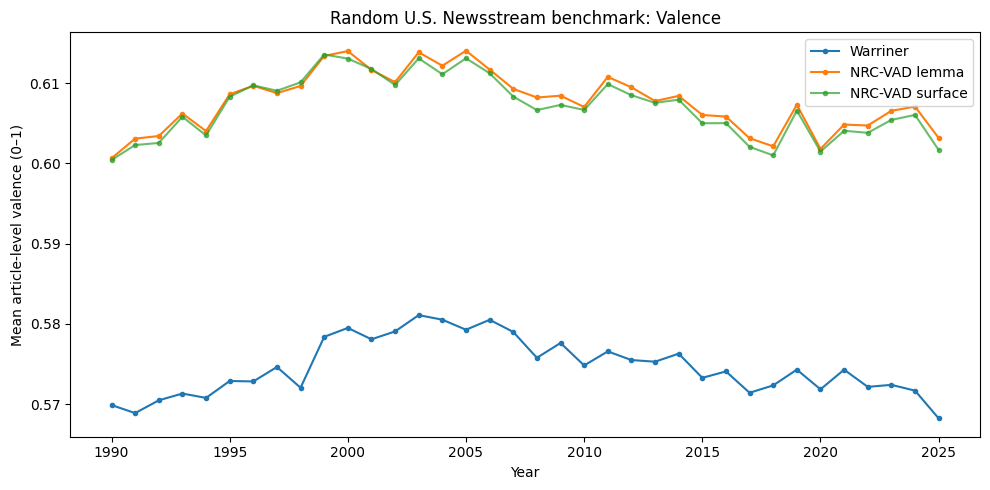

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    comparison["year"],
    comparison["warriner_valence_M"],
    marker="o",
    markersize=3,
    label="Warriner",
)

plt.plot(
    comparison["year"],
    comparison["nrc_lemma_valence_M"],
    marker="o",
    markersize=3,
    label="NRC-VAD lemma",
)

plt.plot(
    comparison["year"],
    comparison["nrc_surface_valence_M"],
    marker="o",
    markersize=3,
    label="NRC-VAD surface",
    alpha=0.7,
)

plt.xlabel("Year")
plt.ylabel("Mean article-level valence (0–1)")
plt.title("Random U.S. Newsstream benchmark: Valence")
plt.legend()
plt.tight_layout()
plt.show()


## 12. Plot the annual Arousal trajectories

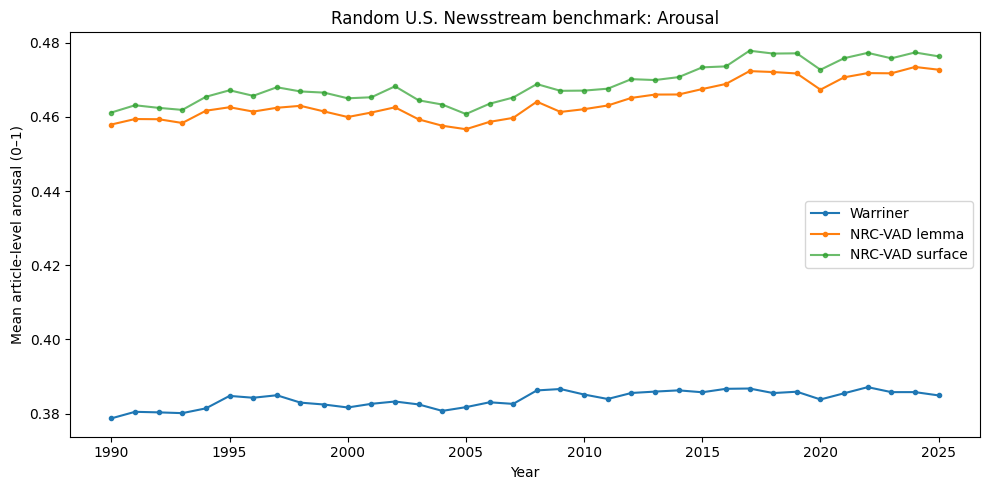

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(
    comparison["year"],
    comparison["warriner_arousal_M"],
    marker="o",
    markersize=3,
    label="Warriner",
)

plt.plot(
    comparison["year"],
    comparison["nrc_lemma_arousal_M"],
    marker="o",
    markersize=3,
    label="NRC-VAD lemma",
)

plt.plot(
    comparison["year"],
    comparison["nrc_surface_arousal_M"],
    marker="o",
    markersize=3,
    label="NRC-VAD surface",
    alpha=0.7,
)

plt.xlabel("Year")
plt.ylabel("Mean article-level arousal (0–1)")
plt.title("Random U.S. Newsstream benchmark: Arousal")
plt.legend()
plt.tight_layout()
plt.show()


## 13. Plot annual lexicon coverage

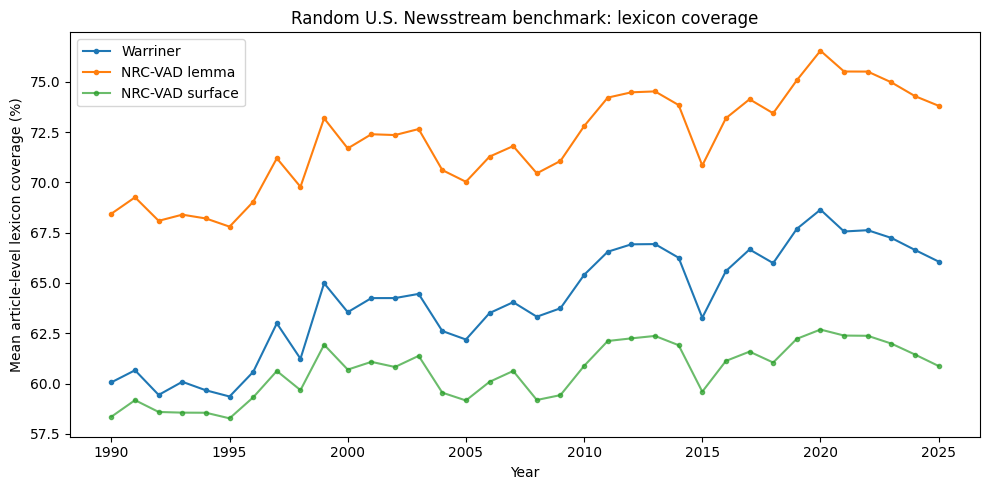

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(
    comparison["year"],
    comparison["warriner_coverage_M"] * 100,
    marker="o",
    markersize=3,
    label="Warriner",
)

plt.plot(
    comparison["year"],
    comparison["nrc_lemma_coverage_M"] * 100,
    marker="o",
    markersize=3,
    label="NRC-VAD lemma",
)

plt.plot(
    comparison["year"],
    comparison["nrc_surface_coverage_M"] * 100,
    marker="o",
    markersize=3,
    label="NRC-VAD surface",
    alpha=0.7,
)

plt.xlabel("Year")
plt.ylabel("Mean article-level lexicon coverage (%)")
plt.title("Random U.S. Newsstream benchmark: lexicon coverage")
plt.legend()
plt.tight_layout()
plt.show()


## 14. Final validation table

Before using the benchmark in the manuscript, verify:

- 1,000 article rows for each year;
- nearly/all articles have valid Valence/Arousal estimates;
- stable lexicon coverage over time;
- duplicate-text counts are not unexpectedly high;
- the formal comparison uses the same year span as the final ADHD model.


In [21]:
validation_columns = [
    "year",
    "n_articles_total",
    "unique_goids",
    "n_duplicate_goid_rows",
    "n_exact_duplicate_text_rows",

    "warriner_valence_n",
    "warriner_coverage_M",
    "warriner_coverage_SD",

    "nrc_lemma_valence_n",
    "nrc_lemma_coverage_M",
    "nrc_lemma_coverage_SD",

    "nrc_surface_valence_n",
    "nrc_surface_coverage_M",
    "nrc_surface_coverage_SD",
]

validation = annual[
    validation_columns
].copy()

display(validation)

problem_years = validation.loc[
    (validation["n_articles_total"] != 1000)
    | (validation["unique_goids"] != 1000)
    | (
        validation["warriner_valence_n"]
        != validation["n_articles_total"]
    )
    | (
        validation["nrc_lemma_valence_n"]
        != validation["n_articles_total"]
    )
]

if len(problem_years):
    print("\nInspect these year(s) before final modelling:")
    display(problem_years)
else:
    print("\nAll 41 years passed the main article-count and scoring checks.")


,year,n_articles_total,unique_goids,n_duplicate_goid_rows,n_exact_duplicate_text_rows,warriner_valence_n,warriner_coverage_M,warriner_coverage_SD,nrc_lemma_valence_n,nrc_lemma_coverage_M,nrc_lemma_coverage_SD,nrc_surface_valence_n,nrc_surface_coverage_M,nrc_surface_coverage_SD
0,1985,989,989,0,0,989,0.638537,0.161065,989,0.717746,0.160522,989,0.604583,0.118330
1,1986,988,988,0,0,988,0.629004,0.163200,988,0.713489,0.161503,988,0.607037,0.118529
2,1987,994,994,0,0,994,0.656567,0.158454,994,0.738936,0.154807,994,0.620936,0.113441
3,1988,992,992,0,0,992,0.655207,0.154541,992,0.740901,0.146995,992,0.624135,0.109236
4,1989,992,992,0,0,992,0.614458,0.175212,992,0.699751,0.173131,992,0.595817,0.128285
5,1990,982,982,0,0,982,0.600653,0.173087,982,0.684437,0.170632,982,0.583560,0.125392
6,1991,980,980,0,0,980,0.606638,0.166272,980,0.692574,0.163546,980,0.591787,0.118745
7,1992,976,976,0,0,976,0.594386,0.171603,976,0.680894,0.166178,976,0.585918,0.124004
8,1993,992,992,0,0,992,0.600912,0.174181,992,0.683954,0.170850,992,0.585583,0.125457
9,1994,977,977,0,0,977,0.596679,0.168172,977,0.682058,0.163230,977,0.585537,0.119754



Inspect these year(s) before final modelling:


,year,n_articles_total,unique_goids,n_duplicate_goid_rows,n_exact_duplicate_text_rows,warriner_valence_n,warriner_coverage_M,warriner_coverage_SD,nrc_lemma_valence_n,nrc_lemma_coverage_M,nrc_lemma_coverage_SD,nrc_surface_valence_n,nrc_surface_coverage_M,nrc_surface_coverage_SD
0,1985,989,989,0,0,989,0.638537,0.161065,989,0.717746,0.160522,989,0.604583,0.118330
1,1986,988,988,0,0,988,0.629004,0.163200,988,0.713489,0.161503,988,0.607037,0.118529
2,1987,994,994,0,0,994,0.656567,0.158454,994,0.738936,0.154807,994,0.620936,0.113441
3,1988,992,992,0,0,992,0.655207,0.154541,992,0.740901,0.146995,992,0.624135,0.109236
4,1989,992,992,0,0,992,0.614458,0.175212,992,0.699751,0.173131,992,0.595817,0.128285
5,1990,982,982,0,0,982,0.600653,0.173087,982,0.684437,0.170632,982,0.583560,0.125392
6,1991,980,980,0,0,980,0.606638,0.166272,980,0.692574,0.163546,980,0.591787,0.118745
7,1992,976,976,0,0,976,0.594386,0.171603,976,0.680894,0.166178,976,0.585918,0.124004
8,1993,992,992,0,0,992,0.600912,0.174181,992,0.683954,0.170850,992,0.585583,0.125457
9,1994,977,977,0,0,977,0.596679,0.168172,977,0.682058,0.163230,977,0.585537,0.119754


In [27]:
# ============================================================
# FINAL ADHD vs GENERAL-NEWS COMPARISON: 1990–2025
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

PROJECT_ROOT = Path("/home/ec2-user/SageMaker/ADHD_conceptual_change")
OUTPUT_ROOT = PROJECT_ROOT / "output"
BASELINE_ROOT = PROJECT_ROOT / "random_news_benchmark"

# ------------------------------------------------------------
# 1. Load ADHD annual Warriner indices
# ------------------------------------------------------------

VALENCE_PATH = OUTPUT_ROOT / "annual_valence_indices.csv"
AROUSAL_PATH = OUTPUT_ROOT / "annual_arousal_indices.csv"

adhd_v = pd.read_csv(VALENCE_PATH)
adhd_a = pd.read_csv(AROUSAL_PATH)

print("Valence columns:")
print(adhd_v.columns.tolist())

print("\nArousal columns:")
print(adhd_a.columns.tolist())

# Keep ADHD only if target column is present
if "target" in adhd_v.columns:
    adhd_v = adhd_v[
        adhd_v["target"].astype(str).str.lower() == "adhd"
    ].copy()

if "target" in adhd_a.columns:
    adhd_a = adhd_a[
        adhd_a["target"].astype(str).str.lower() == "adhd"
    ].copy()

adhd = pd.merge(
    adhd_v[
        ["year", "avg_valence_index"]
    ],
    adhd_a[
        ["year", "avg_arousal_index"]
    ],
    on="year",
    how="inner",
)

adhd = adhd.rename(
    columns={
        "avg_valence_index": "adhd_valence",
        "avg_arousal_index": "adhd_arousal",
    }
)

adhd["year"] = pd.to_numeric(
    adhd["year"],
    errors="coerce",
).astype("Int64")

adhd = adhd[
    adhd["year"].between(1990, 2025)
].copy()

print("\nADHD annual indices:")
display(adhd.head())


# ------------------------------------------------------------
# 2. Load general-news baseline
# ------------------------------------------------------------

GENERAL_PATH = (
    BASELINE_ROOT
    / "GENERAL_NEWS_FOR_ADHD_COMPARISON_1990_2025.csv"
)

general = pd.read_csv(GENERAL_PATH)

general = general.rename(
    columns={
        "warriner_valence_M_1to9": "general_valence",
        "warriner_arousal_M_1to9": "general_arousal",
    }
)

general = general[
    [
        "year",
        "n_articles_total",
        "general_valence",
        "general_arousal",
        "warriner_coverage_M",
    ]
].copy()


# ------------------------------------------------------------
# 3. Merge by year
# ------------------------------------------------------------

merged = pd.merge(
    adhd,
    general,
    on="year",
    how="inner",
)

if len(merged) != 36:
    print(
        f"WARNING: expected 36 matched years (1990–2025), "
        f"found {len(merged)}."
    )

# Baseline-adjusted differences
merged["valence_difference"] = (
    merged["adhd_valence"]
    - merged["general_valence"]
)

merged["arousal_difference"] = (
    merged["adhd_arousal"]
    - merged["general_arousal"]
)

MERGED_OUTPUT = (
    BASELINE_ROOT
    / "ADHD_VS_GENERAL_NEWS_1990_2025.csv"
)

merged.to_csv(
    MERGED_OUTPUT,
    index=False,
)

print("\nMerged ADHD/general-news data:")
display(merged)

print("\nSaved:")
print(MERGED_OUTPUT)


# ------------------------------------------------------------
# 4. Long format for formal interaction models
# ------------------------------------------------------------

val_long = pd.concat(
    [
        merged[["year", "adhd_valence"]]
        .rename(columns={"adhd_valence": "score"})
        .assign(source="ADHD"),

        merged[["year", "general_valence"]]
        .rename(columns={"general_valence": "score"})
        .assign(source="GeneralNews"),
    ],
    ignore_index=True,
)

aro_long = pd.concat(
    [
        merged[["year", "adhd_arousal"]]
        .rename(columns={"adhd_arousal": "score"})
        .assign(source="ADHD"),

        merged[["year", "general_arousal"]]
        .rename(columns={"general_arousal": "score"})
        .assign(source="GeneralNews"),
    ],
    ignore_index=True,
)

# Centre year at midpoint of 1990–2025
MID_YEAR = merged["year"].mean()

for df in [val_long, aro_long]:
    df["year_c"] = df["year"] - MID_YEAR
    df["year_c2"] = df["year_c"] ** 2


# ------------------------------------------------------------
# 5. Linear interaction:
#    does ADHD change differently from general news?
# ------------------------------------------------------------

val_linear = smf.ols(
    "score ~ year_c * C(source)",
    data=val_long,
).fit()

aro_linear = smf.ols(
    "score ~ year_c * C(source)",
    data=aro_long,
).fit()


# ------------------------------------------------------------
# 6. Quadratic interaction:
#    does the CURVATURE differ as well?
# ------------------------------------------------------------

val_quad = smf.ols(
    "score ~ year_c * C(source) + year_c2 * C(source)",
    data=val_long,
).fit()

aro_quad = smf.ols(
    "score ~ year_c * C(source) + year_c2 * C(source)",
    data=aro_long,
).fit()


# ------------------------------------------------------------
# 7. Extract clean interaction results
# ------------------------------------------------------------

def extract_interactions(model, dimension, model_type):

    rows = []

    for term in model.params.index:

        if ":" not in term:
            continue

        if "C(source)" not in term:
            continue

        rows.append({
            "dimension": dimension,
            "model": model_type,
            "term": term,
            "b": model.params[term],
            "SE": model.bse[term],
            "t": model.tvalues[term],
            "p": model.pvalues[term],
            "CI95_low": model.conf_int().loc[term, 0],
            "CI95_high": model.conf_int().loc[term, 1],
            "adj_R2": model.rsquared_adj,
        })

    return rows


interaction_results = pd.DataFrame(
    extract_interactions(
        val_linear,
        "Valence",
        "Linear",
    )
    + extract_interactions(
        aro_linear,
        "Arousal",
        "Linear",
    )
    + extract_interactions(
        val_quad,
        "Valence",
        "Quadratic",
    )
    + extract_interactions(
        aro_quad,
        "Arousal",
        "Quadratic",
    )
)

INTERACTION_OUTPUT = (
    BASELINE_ROOT
    / "ADHD_VS_GENERAL_NEWS_INTERACTION_MODELS_1990_2025.csv"
)

interaction_results.to_csv(
    INTERACTION_OUTPUT,
    index=False,
)

print("\nInteraction results:")
display(interaction_results)

print("\nSaved:")
print(INTERACTION_OUTPUT)


# ------------------------------------------------------------
# 8. Model the baseline-adjusted difference directly
# ------------------------------------------------------------

difference_rows = []

for dimension, outcome in {
    "Valence": "valence_difference",
    "Arousal": "arousal_difference",
}.items():

    d = merged[
        ["year", outcome]
    ].dropna().copy()

    d["year_c"] = d["year"] - d["year"].mean()
    d["year_c2"] = d["year_c"] ** 2

    linear = smf.ols(
        f"{outcome} ~ year_c",
        data=d,
    ).fit()

    quadratic = smf.ols(
        f"{outcome} ~ year_c + year_c2",
        data=d,
    ).fit()

    difference_rows.append({
        "dimension": dimension,

        "linear_year_b":
            linear.params["year_c"],
        "linear_year_p":
            linear.pvalues["year_c"],
        "linear_adj_R2":
            linear.rsquared_adj,

        "quadratic_year_b":
            quadratic.params["year_c"],
        "quadratic_year_p":
            quadratic.pvalues["year_c"],

        "quadratic_year2_b":
            quadratic.params["year_c2"],
        "quadratic_year2_p":
            quadratic.pvalues["year_c2"],

        "quadratic_adj_R2":
            quadratic.rsquared_adj,
    })


difference_results = pd.DataFrame(
    difference_rows
)

DIFFERENCE_OUTPUT = (
    BASELINE_ROOT
    / "ADHD_MINUS_GENERAL_NEWS_TRENDS_1990_2025.csv"
)

difference_results.to_csv(
    DIFFERENCE_OUTPUT,
    index=False,
)

print("\nADHD minus general-news trends:")
display(difference_results)

print("\nSaved:")
print(DIFFERENCE_OUTPUT)

Valence columns:
['target', 'year', 'avg_valence_index', 'se_valence_index', 'normalized_valence_index', 'normalized_se_valence_index', 'eligible_context_tokens', 'warriner_valence_covered_tokens', 'warriner_valence_coverage_proportion']

Arousal columns:
['target', 'year', 'avg_arousal_index', 'se_arousal_index', 'normalized_arousal_index', 'normalized_se_arousal_index', 'eligible_context_tokens', 'warriner_arousal_covered_tokens', 'warriner_arousal_coverage_proportion']

ADHD annual indices:


,year,adhd_valence,adhd_arousal
0,1990,5.733109,4.090750
1,1991,5.737063,4.100932
2,1992,5.762406,4.037887
3,1993,5.681788,4.107742
4,1994,5.501040,4.117625



Merged ADHD/general-news data:


,year,adhd_valence,adhd_arousal,n_articles_total,general_valence,general_arousal,warriner_coverage_M,valence_difference,arousal_difference
0,1990,5.733109,4.090750,982,5.559274,4.029935,0.600653,0.173834,0.060815
1,1991,5.737063,4.100932,980,5.551248,4.044013,0.606638,0.185815,0.056919
2,1992,5.762406,4.037887,976,5.563984,4.042813,0.594386,0.198422,-0.004926
3,1993,5.681788,4.107742,992,5.570729,4.041146,0.600912,0.111058,0.066596
4,1994,5.501040,4.117625,977,5.566394,4.051486,0.596679,-0.065353,0.066140
5,1995,5.572431,4.067826,929,5.583232,4.078310,0.593601,-0.010801,-0.010484
6,1996,5.591571,4.068377,928,5.582778,4.074326,0.605833,0.008794,-0.005949
7,1997,5.477065,4.118017,826,5.597166,4.079707,0.629960,-0.120101,0.038310
8,1998,5.587989,4.111366,946,5.576526,4.063818,0.612365,0.011463,0.047548
9,1999,5.544469,4.145254,937,5.627196,4.059720,0.649896,-0.082727,0.085534



Saved:
/home/ec2-user/SageMaker/ADHD_conceptual_change/random_news_benchmark/ADHD_VS_GENERAL_NEWS_1990_2025.csv

Interaction results:


,dimension,model,term,b,SE,t,p,CI95_low,CI95_high,adj_R2
0,Valence,Linear,year_c:C(source)[T.GeneralNews],0.010073,0.001035,9.732747,1.632932e-14,0.008008,0.012139,0.815982
1,Arousal,Linear,year_c:C(source)[T.GeneralNews],-0.000603,0.000440,-1.369282,1.754168e-01,-0.001481,0.000276,0.750847
2,Valence,Quadratic,year_c:C(source)[T.GeneralNews],0.010073,0.000839,12.006183,2.958621e-18,0.008398,0.011748,0.879074
3,Valence,Quadratic,year_c2:C(source)[T.GeneralNews],-0.000549,0.000090,-6.071200,6.973867e-08,-0.000729,-0.000368,0.879074
4,Arousal,Quadratic,year_c:C(source)[T.GeneralNews],-0.000603,0.000382,-1.576648,1.196580e-01,-0.001366,0.000160,0.812076
5,Arousal,Quadratic,year_c2:C(source)[T.GeneralNews],0.000103,0.000041,2.491080,1.525813e-02,0.000020,0.000185,0.812076



Saved:
/home/ec2-user/SageMaker/ADHD_conceptual_change/random_news_benchmark/ADHD_VS_GENERAL_NEWS_INTERACTION_MODELS_1990_2025.csv

ADHD minus general-news trends:


,dimension,linear_year_b,linear_year_p,linear_adj_R2,quadratic_year_b,quadratic_year_p,quadratic_year2_b,quadratic_year2_p,quadratic_adj_R2
0,Valence,-0.010073,2.752428e-10,0.686040,-0.010073,6.366962e-15,0.000549,9.673431e-08,0.865014
1,Arousal,0.000603,1.727762e-01,0.026138,0.000603,1.479563e-01,-0.000103,2.543678e-02,0.139501



Saved:
/home/ec2-user/SageMaker/ADHD_conceptual_change/random_news_benchmark/ADHD_MINUS_GENERAL_NEWS_TRENDS_1990_2025.csv


## Suggested reporting logic

For the manuscript, the cleanest comparison is:

- **Warriner article benchmark** as the primary random-news control, because the ADHD primary Sentiment/Intensity measures use Warriner;
- **NRC-VAD lemma benchmark** as a higher-coverage sensitivity analysis, because it changes the affective lexicon while holding preprocessing constant;
- **NRC-VAD surface benchmark** as exploratory only, if it materially changes interpretation.

For Breadth, explain that there is no directly equivalent corpus-level control because SIBling Breadth is target-centred. A random-news semantic-diversity index would measure a different construct.
